# IRWA Final Project — Part 1: Text Processing and EDA

* **Part 1 – Data preparation:** clean the text and decide how to handle each field.
* **Part 2 – Exploratory data analysis (EDA).**

The cleaning code is in `irwa_preprocessing.py`, so Part 2 can reuse exactly the same functions for the queries.

In [1]:
import json
import re
import collections
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

for resource in ["stopwords", "punkt_tab"]:
    nltk.download(resource, quiet=True)

from nltk.tokenize import sent_tokenize
from IPython.display import display

import irwa_preprocessing as pp

DATA = Path("../../data")  # dataset folder of the project template
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.max_columns", 30)


def savefig(name):
    """Drop pandas' automatic y-label, then save the figure as figures/<name>.png and show it."""
    for ax in plt.gcf().axes:  # remove the column name pandas puts as y-label
        if ax.get_ylabel() not in ("Count", "query, label"):
            ax.set_ylabel("")
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 0. Load the data

In [2]:
with open(DATA / "fashion_products_dataset.json", encoding="utf-8") as f:
    docs = json.load(f)
raw = pd.DataFrame(docs)
labels = pd.read_csv(DATA / "validation_labels.csv")
QUERIES = {1: "women full sleeve sweatshirt cotton", 2: "men slim jeans blue"}
N = len(raw)

print(f"{N:,} products, {raw.shape[1]} fields | pid unique: {raw.pid.is_unique}")
display(raw.iloc[0])

28,080 products, 17 fields | pid unique: True


_id                                                 fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a
actual_price                                                                       2,999
average_rating                                                                       3.9
brand                                                                               York
category                                                        Clothing and Accessories
crawled_at                                                                 1612987911000
description        Yorker trackpants made from 100% rich combed cotton giving it a ri...
discount                                                                         69% off
images             [https://rukminim1.flixcart.com/image/128/128/jr3t5e80/track-pant/...
out_of_stock                                                                       False
pid                                                                     TKPFCZ9EA7H5FYZH
product_details    [{

Prices, discounts and ratings are stored as text (`"2,999"`, `"69% off"`, `"3.9"`), and missing values are empty strings.

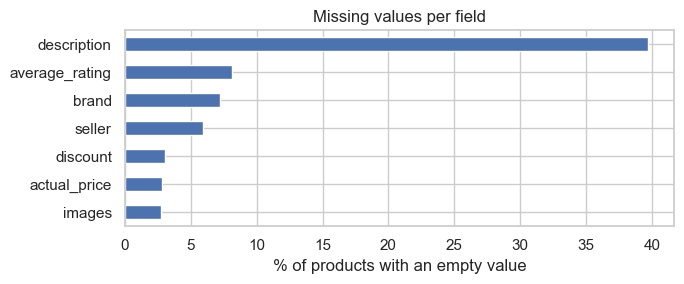

In [3]:
def is_empty(v):
    """True when a value is missing: None, a blank string, or an empty list."""
    return v is None or (isinstance(v, str) and v.strip() == "") or (isinstance(v, list) and len(v) == 0)

missing = raw.map(is_empty).mean().mul(100).round(1)
missing = missing[missing > 0].sort_values()
ax = missing.plot.barh(figsize=(7, 3), color="C0")
ax.set_xlabel("% of products with an empty value")
ax.set_title("Missing values per field")
savefig("missing_values")

---
# PART 1 — Data preparation

## 1.1 Problems found in the raw data

In [4]:
text = raw.title + " " + raw.description
print("texts with words glued by punctuation ('look.Designed'):", text.str.contains(r"[a-z][.,;:][A-Za-z]").sum())
print("spellings of 'T-shirt':")
display(text.str.lower().str.findall(r"\bt[\s\-]?shirts?\b|\btees?\b").explode().value_counts().to_frame("count").T)

texts with words glued by punctuation ('look.Designed'): 1917
spellings of 'T-shirt':


,t-shirt,t-shirts,t shirt,tshirt,tee,tshirts,tees,t shirts
count,19117,3761,2093,1053,819,727,456,230


**Brands are cut off** ("Pu" = Puma, "REEB" = Reebok). The URL starts with the full brand
(`flipkart.com/free-authority-full-sleeve-...`), so `pp.recover_brand` takes the name from there.

In [5]:
brand_full = pd.Series([pp.recover_brand(b, u) for b, u in zip(raw.brand, raw.url)])
alnum = lambda s: s.str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
fixed = alnum(raw.brand) != alnum(brand_full)
print(f"brands completed from the URL: {fixed.sum():,} of {(raw.brand != '').sum():,}")
display(pd.DataFrame({"brand": raw.brand, "recovered": brand_full})[fixed].drop_duplicates().head(8))

brands completed from the URL: 24,741 of 26,071


,brand,recovered
0,York,yorker
34,ANGI,angira
151,Man,manra
172,TRANSPERAN,transperancy
173,DISCOUNT OUTL,discount outlet
250,adidas Origina,adidas originals
309,Fresh Fe,fresh feet
333,SayItLo,sayitloud


**Gender words disagree:** almost every URL says "men", while titles are half "Men", half "Women".

In [6]:
def gender_of(s):
    """Return 'women', 'men' or 'none' from a title or URL. 'women' is checked first."""
    s = (s or "").lower().replace("-", " ")
    return "women" if re.search(r"\bwomen", s) else "men" if re.search(r"\bmen\b", s) else "none"

slug = raw.url.str.extract(r"flipkart\.com/([^/]+)/p/")[0]
display(pd.crosstab(raw.title.map(gender_of).rename("title"), slug.map(gender_of).rename("url")))

url,men,none,women
title,,,
men,12995,0,0
none,0,2044,0
women,12978,0,63


Section 1.6 shows that the relevance labels follow the **title**, so the URL is returned but **not indexed**.

## 1.2 Text pre-processing (point 1)

`pp.preprocess_text` is used for titles, descriptions, product details and (in Part 2) queries:

1. **Lowercase.**
2. **Write a few fashion words in one way:** `t-shirt / t shirt / tee → tshirt`, `sweat shirt → sweatshirt`,
   `polycotton → poly cotton`, `slimfit → slim fit`. Without this, "t-shirt" becomes `t` + `shirt` and every T-shirt
   matches the query "shirt".
3. **Remove punctuation** by replacing it with spaces, so glued words are separated too (`look.Designed → look designed`).
4. **Tokenise** with `split()`, as in the lab sessions.
5. **Remove stop words** (NLTK list). `men` / `women` are kept: they matter a lot for relevance.
6. **Remove numbers and 1-letter tokens** (`100`, `2`, `s`).
7. **Stem** with the Porter stemmer, as in the lab sessions (`jeans → jean`, `printed → print`).

In [7]:
example = raw.loc[0, "title"] + ". " + raw.loc[0, "description"]
print("RAW:", example, "\n")
s = pp.normalize_fashion_words(example.lower())
s = pp.remove_punctuation(s);       print("lowercase, no punctuation:", s, "\n")
t = pp.tokenize(s);                 print("tokenize (split): ", t)
t = pp.remove_stopwords(t);         print("- stop words:     ", t)
t = pp.remove_numbers(t);           print("- numbers/1-letter:", t)
t = pp.stem(t);                     print("stem:             ", t)
print()
for qid, q in QUERIES.items():
    print(f"query_{qid}: {q!r} -> {pp.preprocess_text(q)}")

RAW: Solid Women Multicolor Track Pants. Yorker trackpants made from 100% rich combed cotton giving it a rich look.Designed for Comfort,Skin friendly fabric,itch-free waistband & great for all year round use Proudly made in India 

lowercase, no punctuation: solid women multicolor track pants  yorker trackpants made from 100  rich combed cotton giving it a rich look designed for comfort skin friendly fabric itch free waistband   great for all year round use proudly made in india 

tokenize (split):  ['solid', 'women', 'multicolor', 'track', 'pants', 'yorker', 'trackpants', 'made', 'from', '100', 'rich', 'combed', 'cotton', 'giving', 'it', 'a', 'rich', 'look', 'designed', 'for', 'comfort', 'skin', 'friendly', 'fabric', 'itch', 'free', 'waistband', 'great', 'for', 'all', 'year', 'round', 'use', 'proudly', 'made', 'in', 'india']
- stop words:      ['solid', 'women', 'multicolor', 'track', 'pants', 'yorker', 'trackpants', 'made', '100', 'rich', 'combed', 'cotton', 'giving', 'rich', 'look',

Effect of each step on all titles + descriptions:

In [8]:
counts = {k: collections.Counter() for k in ["lowercase + split", "no punctuation", "no stop words", "no numbers", "stemmed"]}
for s in pd.concat([raw.title, raw.description]):
    t0 = s.lower().split()
    t1 = pp.tokenize(pp.remove_punctuation(pp.normalize_fashion_words(s.lower())))
    t2 = pp.remove_stopwords(t1)
    t3 = pp.remove_numbers(t2)
    for name, toks in zip(counts, [t0, t1, t2, t3, pp.stem(t3)]):
        counts[name].update(toks)
display(pd.DataFrame({"tokens": [sum(c.values()) for c in counts.values()],
                      "vocabulary": [len(c) for c in counts.values()]}, index=list(counts)))

,tokens,vocabulary
lowercase + split,1017425,10606
no punctuation,1032209,6514
no stop words,705869,6386
no numbers,687899,6195
stemmed,687899,4729


## 1.3 Process the whole corpus and keep the output fields (point 2)

For each product we keep the **raw output fields unchanged** (`pid, title, description, brand, category, sub_category,
product_details, seller, out_of_stock, selling_price, discount, actual_price, average_rating, url`) and add the
**processed fields** used for search.

In [9]:
corpus = pp.preprocess_corpus(docs)
print("columns:", list(corpus.columns))
display(corpus.loc["TKPFCZ9EA7H5FYZH", ["title_terms", "details_terms", "brand_terms", "sub_category_terms",
                                        "selling_price_num", "actual_price_num", "discount_pct",
                                        "average_rating_num", "in_stock"]])
corpus.to_pickle(DATA / "processed_corpus.pkl")  # used in Part 2

columns: ['pid', 'title', 'description', 'brand', 'category', 'sub_category', 'product_details', 'seller', 'out_of_stock', 'selling_price', 'discount', 'actual_price', 'average_rating', 'url', 'title_terms', 'description_terms', 'details_terms', 'brand_terms', 'sub_category_terms', 'all_terms', 'brand_full', 'details', 'selling_price_num', 'actual_price_num', 'discount_pct', 'average_rating_num', 'in_stock']


title_terms                           [solid, women, multicolor, track, pant]
details_terms         [elast, side, pocket, cotton, blend, solid, multicolor]
brand_terms                                                          [yorker]
sub_category_terms                                               [bottomwear]
selling_price_num                                                       921.0
actual_price_num                                                       2999.0
discount_pct                                                             69.0
average_rating_num                                                        3.9
in_stock                                                                 True
Name: TKPFCZ9EA7H5FYZH, dtype: object

## 1.4 category, sub_category, brand, product_details, seller (point 3)

A field only helps ranking if it is **distinctive**: a value shared by almost every product has an IDF near 0.

In [10]:
flat = raw.product_details.map(pp.flatten_details)

def stats(name, values):
    """Distinct values, most common value and its share, and the median IDF of one field."""
    values = values[values.str.strip() != ""]
    share = values.value_counts(normalize=True)
    idf = np.log10(N / values.map(values.value_counts()))
    return {"field": name, "distinct values": values.nunique(), "most common": share.index[0],
            "its share": f"{share.iloc[0]:.1%}", "median IDF": round(float(idf.median()), 2)}

display(pd.DataFrame([
    stats("category", raw.category),
    stats("sub_category", raw.sub_category),
    stats("brand", brand_full),
    stats("seller", raw.seller),
    stats("details: Fabric", flat.map(lambda d: d.get("Fabric", ""))),
    stats("details: Color", flat.map(lambda d: d.get("Color", ""))),
]).set_index("field"))

colours = {"black", "blue", "white", "red", "green", "grey", "pink", "purpl", "yellow", "solid", "sport"}
clash = corpus.brand_terms.map(lambda ts: bool(set(ts) & colours))
print(f"products whose brand contains a colour/attribute word: {clash.sum():,} ({clash.mean():.1%}), e.g.",
      corpus.brand_full[clash].value_counts().head(4).index.tolist())
print(f"brands sold per seller (average): {raw[raw.seller != ''].assign(b=brand_full).groupby('seller').b.nunique().mean():.2f}")

,distinct values,most common,its share,median IDF
field,,,,
category,4,Clothing and Accessories,96.6%,0.02
sub_category,24,Topwear,54.5%,0.26
brand,323,ecko unltd,3.6%,2.00
seller,534,RetailNet,5.3%,2.07
details: Fabric,244,Cotton Blend,41.0%,0.75
details: Color,352,Multicolor,17.8%,1.35


products whose brand contains a colour/attribute word: 2,031 (7.2%), e.g. ['true blue', 'black beatle', 't10 sports', 'purple state']
brands sold per seller (average): 1.20


**Options:** (A) merge all fields into one text field: simple, but a title match counts the same as a seller match,
and useless values make every document longer; (B) index each field separately: each field can get its own weight,
but there is more to tune; (C) use the field only as a filter.

**Our choice: separate fields, plus one merged field (`all_terms`) for simple models.**

| field | decision | why |
|---|---|---|
| category | filter only | 96.6% of products have the same value, IDF ≈ 0 |
| sub_category | text, low weight | only 24 coarse values, but on topic ("Bottomwear") |
| brand | text, medium weight (name from URL) | very distinctive, but some brands are colour words (*True Blue*, *Black Beatle*) and would wrongly match "blue jeans" if mixed with the main text |
| product_details | text, high weight (values only) | holds the attributes users search for: fabric, colour, sleeve, fit, gender. Identifiers and boilerplate keys (Style Code, Fabric Care, Country of Origin...) are skipped |
| seller | filter only | mostly repeats the brand (1.2 brands per seller) and nobody searches by seller |

## 1.5 out_of_stock, prices, discount, rating (point 4)

**Not indexed as text.** `"69% off"` would become the useless terms `69` and `off`. Instead they are converted to
numbers (`selling_price_num`, `actual_price_num`, `discount_pct`, `average_rating_num`, `in_stock`) to be used as
filters ("under 1000", "in stock") and ranking signals. A missing rating stays empty — it is **not** a rating of 0.

In [11]:
display(corpus[["selling_price_num", "actual_price_num", "discount_pct", "average_rating_num"]].describe().T.round(2))
check = (100 * (1 - corpus.selling_price_num / corpus.actual_price_num)).round()
print("discount that does not match the prices:", int(((check - corpus.discount_pct).abs() > 1).sum()), "products")

,count,mean,std,min,25%,50%,75%,max
selling_price_num,28078.0,705.64,549.68,99.0,390.0,545.0,820.0,7999.0
actual_price_num,27303.0,1455.53,939.98,150.0,849.0,1199.0,1799.0,12999.0
discount_pct,27225.0,50.26,16.89,1.0,40.0,53.0,63.0,87.0
average_rating_num,25819.0,3.63,0.66,1.0,3.2,3.8,4.1,5.0


discount that does not match the prices: 3 products


## 1.6 What the validation labels tell us

For each labelled product: which share of the query terms appears in each field?

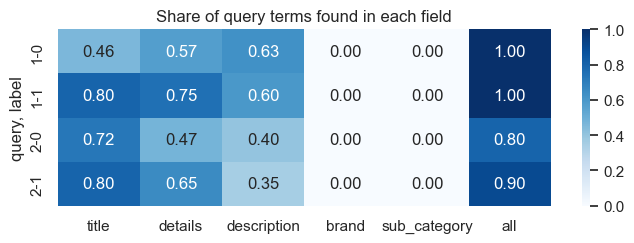

Query 2 – share relevant by gender in title:


,mean,size
title_gender,,
men,0.78,9
women,0.27,11


Query 1 – share relevant by product type in title:


,mean,size
is_sweatshirt,,
False,0.00,4
True,0.81,16


In [12]:
lab = labels.merge(corpus.drop(columns=["title"]), left_on="pid", right_index=True)
rows = []
for _, r in lab.iterrows():
    q = set(pp.preprocess_text(QUERIES[r.query_id]))
    row = {"query": r.query_id, "label": r.labels}
    for f in ["title", "details", "description", "brand", "sub_category", "all"]:
        row[f] = len(q & set(r[f + "_terms"])) / len(q)
    rows.append(row)
coverage = pd.DataFrame(rows).groupby(["query", "label"]).mean()

plt.figure(figsize=(7, 2.6))
sns.heatmap(coverage, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Share of query terms found in each field")
plt.ylabel("query, label")
savefig("validation_field_coverage")

lab["title_gender"] = lab.title_terms.map(lambda t: "women" if "women" in t else "men")
lab["is_sweatshirt"] = lab.title_terms.map(lambda t: "sweatshirt" in t)
print("Query 2 – share relevant by gender in title:")
display(lab[lab.query_id == 2].groupby("title_gender").labels.agg(["mean", "size"]).round(2))
print("Query 1 – share relevant by product type in title:")
display(lab[lab.query_id == 1].groupby("is_sweatshirt").labels.agg(["mean", "size"]).round(2))

* **Title and product_details** hold most query terms, and more for relevant products → highest weights.
* The **gender in the title** decides a lot: for "men slim jeans blue", *Men* products are relevant 78% of the time,
  *Women* products 27%. For query 1, T-shirts are never relevant. So `men`/`women` must stay, and T-shirts must not
  match "sweatshirt".
* **description** has as many query terms for non-relevant as for relevant products → low weight.
* **brand / sub_category** contain no query terms here → low weight.

---
# PART 2 — Exploratory Data Analysis

## 2.1 Categories

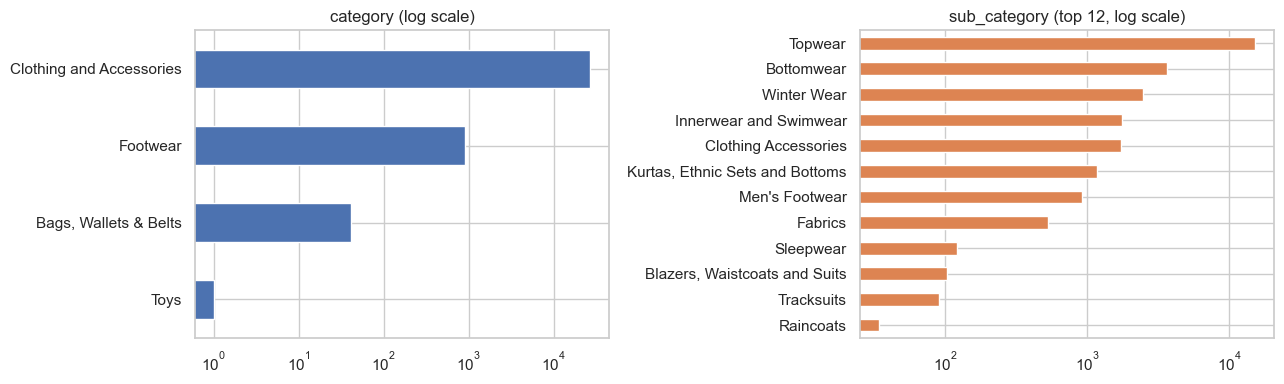

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
raw.category.value_counts().plot.barh(ax=axes[0], logx=True, title="category (log scale)")
raw.sub_category.value_counts().head(12).plot.barh(ax=axes[1], logx=True, color="C1", title="sub_category (top 12, log scale)")
for ax in axes:
    ax.invert_yaxis()
savefig("categories")

Almost everything is clothing (96.6%), and *Topwear* alone is 55% of the products.

## 2.2 Text length, sentences and vocabulary

title: 6.9 words on average
description: empty for 39.7% of products, 50.9 words on average when present
sentences: 3.3 per description, 15.5 words on average
vocabulary after pre-processing: 6,343 terms


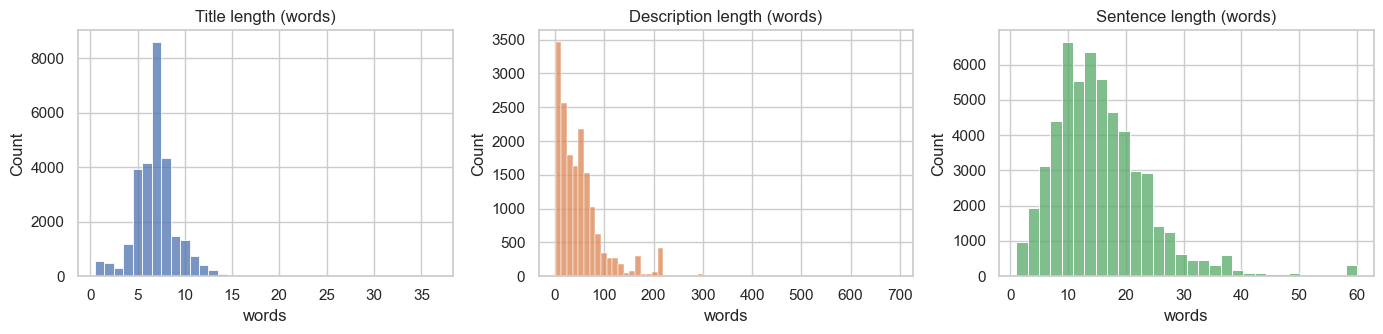

In [14]:
def n_words(s):
    """Number of words after punctuation is replaced by spaces."""
    return len(pp.tokenize(pp.remove_punctuation(s)))

desc = raw.description[raw.description.str.strip() != ""]
sentences = [s for d in desc for s in sent_tokenize(re.sub(r"([.!?])(?=[A-Za-z])", r"\1 ", d))
             if n_words(s) > 0]
title_len = raw.title.map(n_words)
desc_len = desc.map(n_words)
sent_len = pd.Series([n_words(s) for s in sentences])
vocab = collections.Counter(t for ts in corpus.all_terms for t in ts)

print(f"title: {title_len.mean():.1f} words on average")
print(f"description: empty for {1 - len(desc) / N:.1%} of products, {desc_len.mean():.1f} words on average when present")
print(f"sentences: {len(sentences) / len(desc):.1f} per description, {sent_len.mean():.1f} words on average")
print(f"vocabulary after pre-processing: {len(vocab):,} terms")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
sns.histplot(title_len, discrete=True, ax=axes[0]).set_title("Title length (words)")
sns.histplot(desc_len, bins=60, ax=axes[1], color="C1").set_title("Description length (words)")
sns.histplot(sent_len.clip(upper=60), bins=30, ax=axes[2], color="C2").set_title("Sentence length (words)")
for ax in axes:
    ax.set_xlabel("words")
savefig("lengths")

## 2.3 Most frequent words

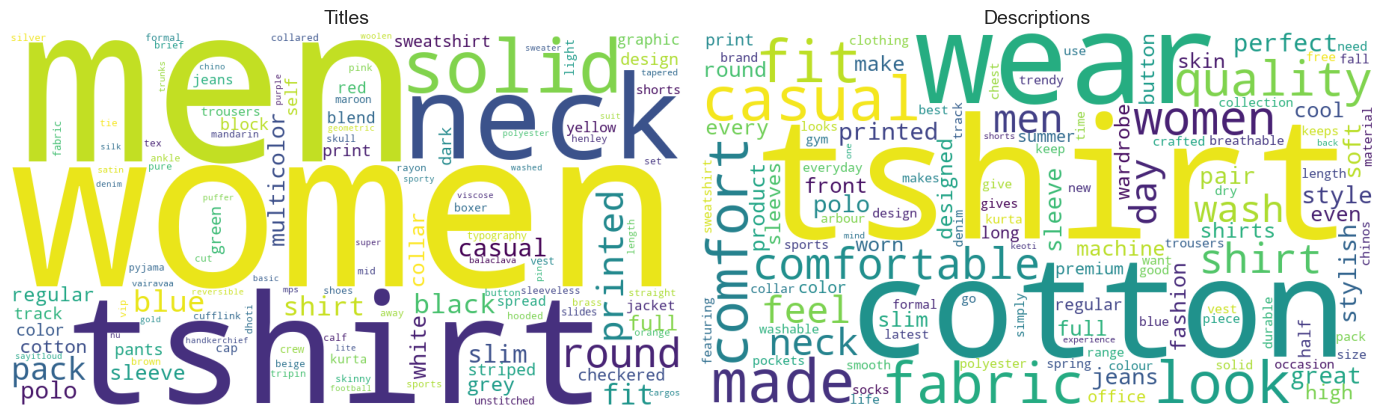

In [15]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, name in [(axes[0], raw.title, "Titles"), (axes[1], raw.description, "Descriptions")]:
    freq = collections.Counter(t for x in col for t in pp.preprocess_text(x, do_stem=False))
    wc = WordCloud(width=900, height=500, background_color="white", max_words=120, random_state=0)
    ax.imshow(wc.generate_from_frequencies(freq)); ax.axis("off"); ax.set_title(name, fontsize=14)
savefig("wordclouds")

Titles are about gender, product type and style (`men`, `women`, `tshirt`, `neck`, `solid`). Descriptions add
marketing words (`comfort`, `look`, `quality`) that are not useful for search.

## 2.4 Product attributes

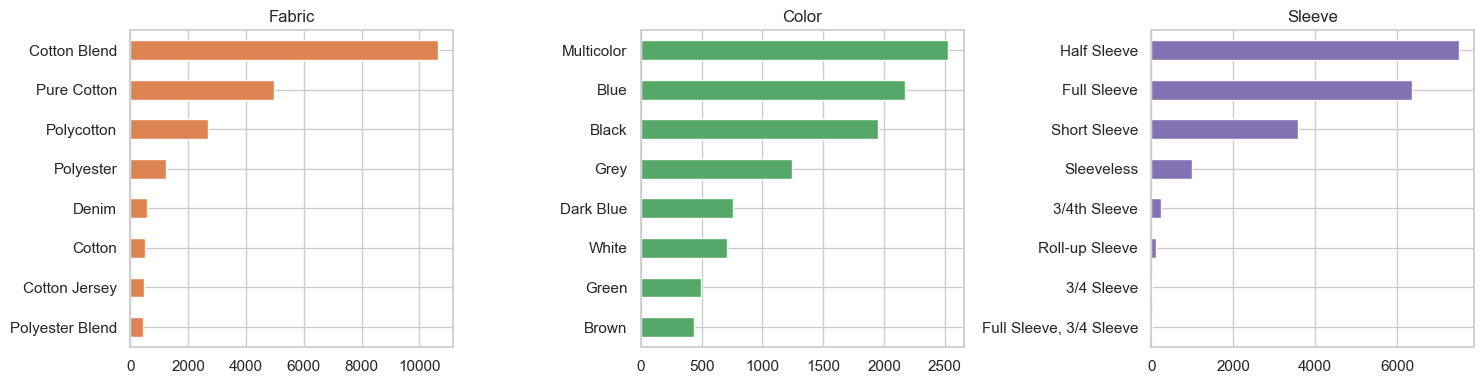

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, key, color in zip(axes, ["Fabric", "Color", "Sleeve"], ["C1", "C2", "C4"]):
    flat.map(lambda d: d.get(key)).dropna().value_counts().head(8).sort_values().plot.barh(ax=ax, color=color, title=key)
savefig("product_details")

## 2.5 Prices, discounts and ratings

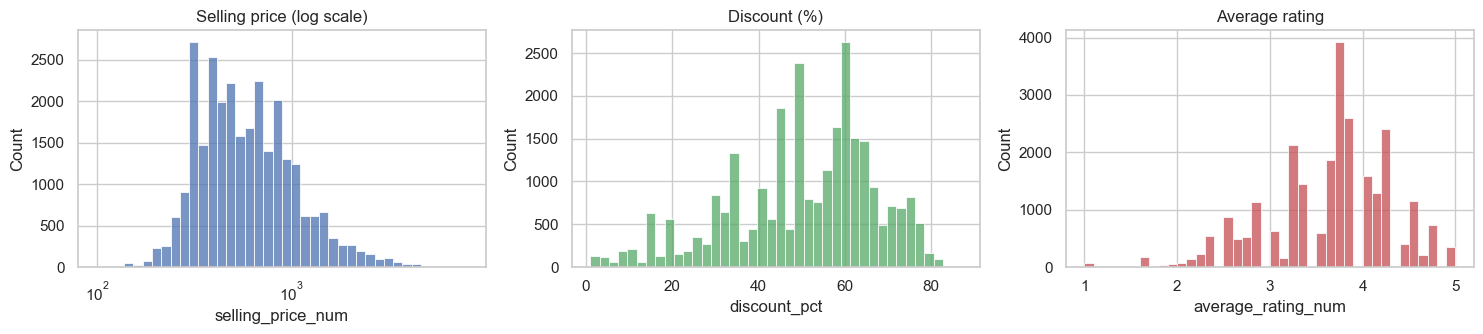

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
sns.histplot(corpus.selling_price_num, log_scale=True, bins=40, ax=axes[0]).set_title("Selling price (log scale)")
sns.histplot(corpus.discount_pct, bins=40, ax=axes[1], color="C2").set_title("Discount (%)")
sns.histplot(corpus.average_rating_num, bins=40, ax=axes[2], color="C3").set_title("Average rating")
savefig("prices_ratings")

Prices are low (median ₹545), discounts are big (median 52%) and ratings are mostly between 3.2 and 4.1.

## 2.6 Rankings

Top 5 by rating:


,title,brand_full,selling_price_num,discount_pct,average_rating_num
pid,,,,,
KTAFAKGUKA2SXSEQ,Men Solid Cotton Blend Pathani Kurta (Blue),purple state,449.0,82.0,5.0
BXRFKYKYF3SGUMFH,Printed Men Boxer (Pack of 1),sayitloud,249.0,78.0,5.0
TSHFNJ9ZEUZG3CPU,Printed Women Round Neck Multicolor T-Shirt,yellowvibes,275.0,77.0,5.0
TSHFU5AF8KZC5FYH,Printed Women Round Neck Black T-Shirt,pixfab,289.0,77.0,5.0
TSHFTT2JATXKUHEV,Solid Women Round Neck Black T-Shirt,pixfab,288.0,77.0,5.0


Top 5 by discount:


,title,brand_full,selling_price_num,discount_pct,average_rating_num
pid,,,,,
TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,jack royal,128.0,87.0,3.0
TSHFMFXGFJ7G2ABK,Printed Women Round Neck Grey T-Shirt,jack royal,136.0,86.0,4.1
TSHFMFT7VASAHBH3,Printed Women Round Neck White T-Shirt,jack royal,136.0,86.0,4.7
TSHFGH6T3CVGDXS9,Printed Men Round Neck Multicolor T-Shirt (Pack of 2),yellowvibes,449.0,85.0,3.2
CAPE9YWMURE4FKAJ,Solid Balclava Cap,graceway,228.0,84.0,4.3


Top 5 most expensive:


,title,brand_full,selling_price_num,discount_pct,average_rating_num
pid,,,,,
TKTFZ3YGGMMNBYEZ,Solid Women Track Suit,reebok,7999.0,20.0,2.7
BZRFVAX2QGTEGHRH,Checkered Single Breasted Party Women Full Sleeve Blazer (Grey),true blue,7998.0,NaN,2.6
JCKFQF5KMJJ349H8,Full Sleeve Solid Women Casual Jacket,puma,7799.0,40.0,3.7
SWSFUMFGQFKVZGYH,Full Sleeve Printed Men Sweatshirt,puma,7799.0,40.0,4.5
JEAF8S4GWU5YKQTF,Skinny Men Blue Jeans,gas,7794.0,40.0,4.2


Products rated 5.0: 329


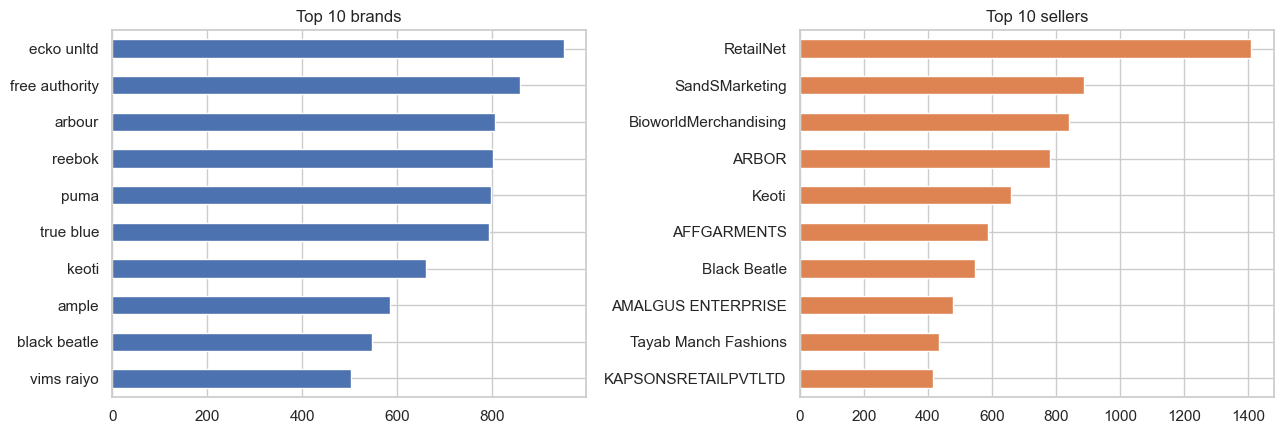

In [18]:
cols = ["title", "brand_full", "selling_price_num", "discount_pct", "average_rating_num"]
print("Top 5 by rating:")
display(corpus.sort_values(["average_rating_num", "discount_pct"], ascending=False)[cols].head(5))
print("Top 5 by discount:")
display(corpus.sort_values("discount_pct", ascending=False)[cols].head(5))
print("Top 5 most expensive:")
display(corpus.sort_values("selling_price_num", ascending=False)[cols].head(5))
print("Products rated 5.0:", (corpus.average_rating_num == 5).sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
corpus.brand_full[corpus.brand_full != ""].value_counts().head(10).sort_values().plot.barh(ax=axes[0], title="Top 10 brands")
raw.seller[raw.seller != ""].value_counts().head(10).sort_values().plot.barh(ax=axes[1], color="C1", title="Top 10 sellers")
savefig("brands_sellers")

Many products tie at 5.0 and there is no number of reviews, so rating alone is a weak ranking signal.

## 2.7 Out of stock

out of stock: 1,644 products (5.9%)


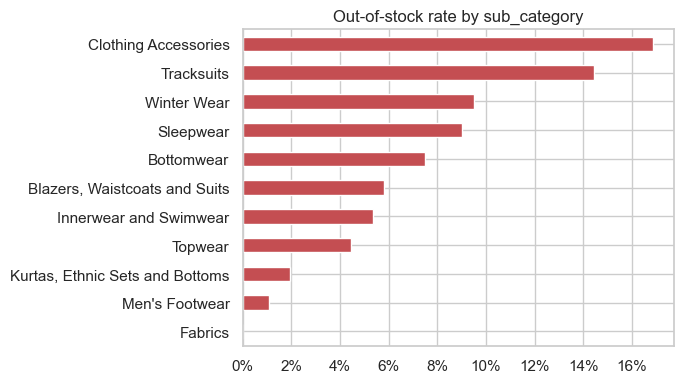

In [19]:
print(f"out of stock: {(~corpus.in_stock).sum():,} products ({(~corpus.in_stock).mean():.1%})")
rate = corpus.groupby("sub_category").agg(n=("pid", "size"), oos=("in_stock", lambda s: 1 - s.mean()))
ax = rate[rate.n >= 50].oos.sort_values().plot.barh(figsize=(7, 4), color="C3", title="Out-of-stock rate by sub_category")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
savefig("out_of_stock")

## 2.8 Duplicates

In [20]:
print(f"products sharing their title with another product: {raw.title.duplicated(keep=False).mean():.1%}")
print(f"non-empty descriptions shared with another product: {desc.duplicated(keep=False).mean():.1%}")

products sharing their title with another product: 87.1%
non-empty descriptions shared with another product: 77.4%


Most products are colour/size variants of the same item, so many will get exactly the same text score in Part 2.

## 2.9 Named-entity recognition (spaCy)

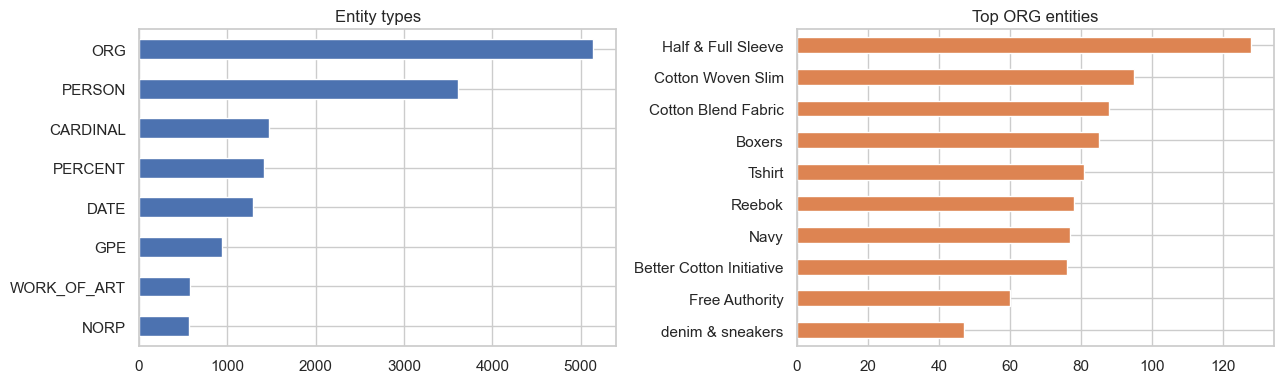

In [21]:
import spacy

nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])
entities = collections.defaultdict(collections.Counter)
for doc in nlp.pipe(desc.unique(), batch_size=256):
    for ent in doc.ents:
        entities[ent.label_][ent.text.strip()] += 1

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pd.Series({k: sum(v.values()) for k, v in entities.items()}).nlargest(8).sort_values().plot.barh(ax=axes[0], title="Entity types")
pd.Series(dict(entities["ORG"].most_common(10))).sort_values().plot.barh(ax=axes[1], color="C1", title="Top ORG entities")
savefig("ner")

spaCy is trained on news and makes many mistakes on product text: "Cotton Blend Fabric" and "Tshirt" are tagged as
organisations. It does find real brands (Reebok, Free Authority), but the brand field is a more reliable source.

## Summary

* Same cleaning for documents and queries; fashion words normalised; `men`/`women` kept.
* Title, product details, brand and sub_category are separate text fields (plus a merged `all_terms`).
  Category and seller are filters. The URL is not indexed.
* Prices, discount, rating and stock are numbers for filtering and ranking, not text.
* The processed corpus is saved in `data/processed_corpus.pkl`.